# Predicting Buy Now, Pay Later Use Among US Adults from Financial and Demographic Characteristics
**Binary classification with imbalanced classes** | Module 6COSC017C-n, Machine Learning and Data Analytics, CW1

| Section | | Section | |
|---|---|---|---|
| 1 | Project introduction | 9 | Baseline model |
| 2 | Library imports | 10 | Model training |
| 3 | Data loading | 11 | Hyperparameter tuning |
| 4 | Dataset understanding | 12 | Class imbalance experiments |
| 5 | Exploratory Data Analysis | 13 | Model evaluation |
| 6 | Feature selection | 14 | Explainable AI |
| 7 | Data preprocessing | 15 | Ethical considerations |
| 8 | Train-test split | 16 | Final conclusions |

*How to run:* install `requirements.txt`, then Run All from this folder. A full run takes roughly 10-15 minutes on a 4-core computer.
Reusable code lives in `../src/bnpl/` and is shared with the Streamlit app, so the notebook and the app cannot disagree.

## 1. Project introduction
**Research question.** To what extent can financial and demographic characteristics identify US adults who report having used Buy Now, Pay Later (BNPL) in the past year, and which characteristics are most strongly associated with that use?

**Aim.** Build, compare and explain classification models for past-year BNPL use, without leakage and with honest evaluation under class imbalance.

**Objectives.** (1) Describe BNPL use in SHED 2025. (2) Prepare a documented, leakage-free feature set. (3) Compare Logistic Regression, Decision Tree, Random Forest and Gradient Boosting with a dummy baseline. (4) Test class-imbalance strategies and decision thresholds. (5) Explain the final model and audit it across groups. (6) Deploy it in an interactive application.

**Business case.** Product, policy and consumer-protection teams need to know who relies on BNPL. Only about one adult in six uses it, so the practical question is how many users a model can find and how many false alarms that costs.

**Unit of analysis:** one adult respondent. **Target:** `BNPL1` (Yes/No). **Design:** cross-sectional survey, so the models describe *reported past use*. They do not forecast adoption, and associations are not causes. This is not a credit-risk model.

## 2. Library imports

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
ROOT = ROOT if (ROOT / "src").exists() else ROOT.parent      # works from the project folder or from notebooks/
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")                            # hide library deprecation messages only

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, imblearn, shap
from IPython.display import display, Markdown

from bnpl import config as cfg, data, eda, experiments as ex, pipeline as pl, plots

pd.set_option("display.max_columns", 60, "display.max_colwidth", 90, "display.width", 200)
np.random.seed(cfg.SEED)
print("python", sys.version.split()[0], "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| imbalanced-learn", imblearn.__version__, "| shap", shap.__version__, "| seed", cfg.SEED)

python 3.12.10 | pandas 3.1.1 | scikit-learn 1.9.1 | imbalanced-learn 0.14.2 | shap 0.54.1 | seed 42


## 3. Data loading
The CSV is read directly from the unmodified official ZIP. A SHA-256 check proves the file is the one downloaded from the Federal Reserve Board on 24 November 2026.

In [2]:
assert data.raw_sha256() == cfg.RAW_SHA256, "The raw file differs from the official download"
raw = data.load_raw()                       # all 815 columns
print("Rows, columns:", raw.shape, "| survey year:", raw["year"].unique(), "| fielded in month:", raw["field_month"].unique())
raw.iloc[:5, :14]

Rows, columns: (12934, 815) | survey year: [2025] | fielded in month: [10]


,shedid,duration,weight,weight_pop,panel_weight,panel_weight_pop,xlaptop,L0_a,L0_b,L0_c,L0_d,L0_e,L0B_a,L0B_b
0,202304484,1922,0.6467,13225.3400,NaN,NaN,No,Yes,No,No,No,No,NaN,NaN
1,202204577,189270,0.9687,19810.3406,0.9357,56011.816,No,No,No,No,No,No,NaN,NaN
2,202301342,4240,1.0129,20715.6590,NaN,NaN,No,No,No,Yes,No,No,NaN,NaN
3,202500830,591,1.0278,21020.6151,NaN,NaN,No,Yes,No,No,No,No,NaN,NaN
4,202504363,2508,0.7688,15722.4241,NaN,NaN,No,Yes,No,No,No,No,NaN,NaN


## 4. Dataset understanding
SHED 2025 was collected for the Board by Ipsos through the probability-based KnowledgePanel (Board of Governors, 2026). Variables and codes below were checked against the official codebook (`data/docs/SHED_2025codebook.pdf`).

In [3]:
flags = [c for c in raw.columns if c.endswith("_iflag")]
print("Data types:", raw.dtypes.astype(str).value_counts().to_dict())
print("Survey variables:", raw.shape[1] - len(flags), "| imputation flags:", len(flags))
print("Exact duplicate rows:", raw.duplicated().sum(), "| duplicate respondent IDs:", raw["shedid"].duplicated().sum())

# Target variable and its coding
t = raw["BNPL1"].value_counts().rename("n").to_frame()
t["share"] = (t["n"] / len(raw)).round(4)
display(t)
print("Target answers imputed by the survey team:", int(raw["BNPL1_iflag"].sum()))

Data types: {'str': 426, 'int64': 370, 'float64': 19}
Survey variables: 458 | imputation flags: 357


Exact duplicate rows: 0 | duplicate respondent IDs: 0


,n,share
BNPL1,,
No,10930,0.8451
Yes,2004,0.1549


Target answers imputed by the survey team: 31


In [4]:
# Leakage check: which variables exist only for BNPL users?
users = raw["BNPL1"].eq("Yes")
leak = pd.DataFrame({"answered by users": raw.loc[users, data.BNPL_FOLLOWUPS].notna().mean(),
                     "answered by non-users": raw.loc[~users, data.BNPL_FOLLOWUPS].notna().mean()})
display(leak.round(3).T)

,BNPL3,BNPL3A,BNPL1A,BNPL4_a,BNPL4_b,BNPL4_c,BNPL4_d,BNPL4_e,BNPL4_f,BNPL4_g,BNPL5,BNPL6_a,BNPL6_b,BNPL6_c,BNPL6_d,BNPL6_e,BNPL6_f,BNPL6_g,BNPL7_a,BNPL7_b
answered by users,1.0,0.243,0.27,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.966,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
answered by non-users,0.0,0.000,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


**Finding.** All 20 follow-up questions are blank for every non-user. Using any of them would let a model "predict" the target perfectly by checking whether a cell is blank. They are excluded. This is *target leakage*: the predictor would not exist without the answer.

In [5]:
df, log = data.clean(data.load_raw(data.RAW_COLS))     # documented, row-wise cleaning (section 7 explains each rule)
df = data.load_clean(refresh=True)                     # save and reload, so the app uses exactly this table
fd, excluded = data.feature_dictionary(raw[data.RAW_COLS], df)
ex.save(fd, "feature_dictionary"); ex.save(excluded, "excluded_variables")
display(fd[["Feature", "Source variable(s)", "Description", "Type", "Missing-value treatment", "Reason"]])

,Feature,Source variable(s),Description,Type,Missing-value treatment,Reason
0,bnpl_user,BNPL1,"In the past year, used a 'Buy Now, Pay Later' service to buy something (Yes=1, No=0)",Target (binary),31 imputed answers dropped,TARGET
1,age,ppage,Age in years,Numeric,None missing; median imputer as safeguard,BNPL is a retail-credit product with a known age gradient
2,household_size,"pphhsize, L0_a, L0_b","People in the household, raised to the minimum implied by partner/children",Numeric,None; winsorised at training 99th percentile,Spending needs; needed to equivalise income
3,children_u18,"ppkid017, L0_b",Children aged 0-17 in the household,Numeric,No missing values,Family spending pressure
4,afs_count,BK2_a to BK2_e,"Count of: non-bank money order, non-bank check cashing, payday loan, pawn/auto-title l...",Numeric 0-5,No missing values,Use of alternatives to mainstream credit
5,medical_skips,E1_a to E1_e,Count of care types gone without because of cost (past 12 months),Numeric 0-5,No missing values,Material hardship indicator
6,income_band,I40,"Respondent and spouse/partner total income, past 12 months (15 bands)",Ordinal,None; mode safeguard,Core affordability variable
7,education,"educ_4cat, ED0","Education, 4 categories",Ordinal,"Implausible values set missing, then most frequent value",Socio-economic position
8,financial_wellbeing,B2,How well managing financially these days,Ordinal,No missing values,Headline SHED well-being measure
9,change_vs_last_year,B3,Better or worse off than 12 months ago,Ordinal,No missing values,Direction of finances


In [6]:
# Validation: our survey-weighted BNPL rates against the Fed's published Table 41
val = ex.save(eda.fed_validation(df), "fed_validation")
display(val)
print("Largest absolute difference:", val["Difference"].abs().max(), "percentage points (published figures are rounded)")

,Group,Our weighted rate (%),n,Fed published (%),Difference
0,All adults,16.5,12903,16,0.5
1,Asian,10.6,656,11,-0.4
2,Black,29.3,1505,29,0.3
3,Hispanic,25.9,1750,26,-0.1
4,White,11.5,8634,12,-0.5
5,Female,18.9,6528,19,-0.1
6,Male,13.9,6375,14,-0.1
7,18-29,21.7,2086,22,-0.3
8,30-44,21.3,2991,21,0.3
9,45-59,16.4,2957,17,-0.6


Largest absolute difference: 0.6 percentage points (published figures are rounded)


**Why this matters.** Our weighted rates match the published ones to within 0.6 percentage points for all 15 groups. That is independent evidence that the file, target and weights are read correctly. Weights are used for *population estimates*; model training uses unweighted rows, and section 13 tests whether that choice matters.

## 5. Exploratory Data Analysis
### 5.1 Target and class imbalance
*Purpose:* show how rare the positive class is, because this decides which metrics are meaningful.

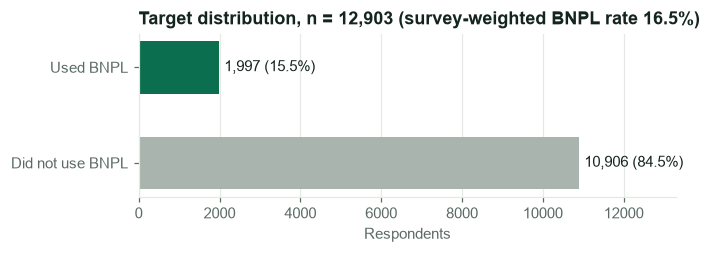

In [7]:
fig = plots.target(df); plt.show()

Only 15.5% of respondents (1,997 of 12,903) used BNPL; weighted to US adults it is 16.5%. A model that always answers "non-user" would be 84.5% accurate and useless. Accuracy therefore cannot be the main metric.

### 5.2 Missing values
*Purpose:* separate blanks that mean something from answers that are really missing.

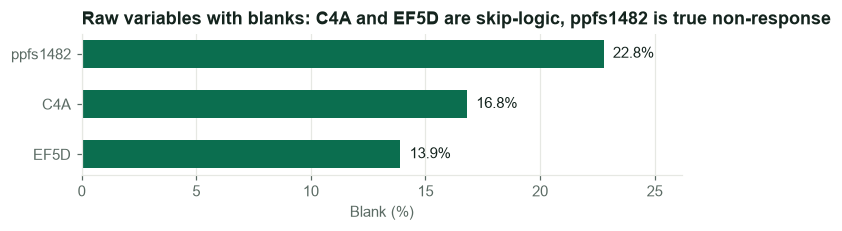

C4A blank exactly when there is no credit card : True
EF5D blank exactly when bills were not all paid: True


In [8]:
fig = plots.missing(raw[data.RAW_COLS]); plt.show()
print("C4A blank exactly when there is no credit card :", (raw["C4A"].isna() == raw["C2A"].eq("No")).all())
print("EF5D blank exactly when bills were not all paid:", (raw["EF5D"].isna() == raw["EF5C"].eq("No")).all())

Two of the three variables with blanks are *skip logic*: the question was not asked because of an earlier answer. Imputing them would invent answers. They are recoded into their own category. Only the self-rated credit score (`ppfs1482`, 22.8%) is true non-response.

### 5.3 Descriptive statistics
*Purpose:* central tendency and spread of the numeric inputs, and a first look for outliers.

In [9]:
desc = eda.descriptive(df)
ex.save(desc.reset_index(names="Variable"), "descriptive")
display(desc.round(2))
display(df[list(cfg.ORDINALS) + cfg.NOMINAL].describe().T)

,count,mean,median,mode,std,variance,min,25%,75%,max,skew,IQR outliers
Age,12903.0,51.32,52.0,59.0,18.17,330.24,18.0,36.0,66.0,98.0,-0.02,0
Household size,12903.0,2.74,2.0,2.0,1.45,2.09,1.0,2.0,4.0,12.0,1.36,125
Children under 18,12903.0,0.52,0.0,0.0,0.98,0.95,0.0,0.0,1.0,9.0,2.35,691
Alternative financial services used (0-5),12903.0,0.22,0.0,0.0,0.62,0.38,0.0,0.0,0.0,5.0,3.55,1931
Types of care skipped due to cost (0-5),12903.0,0.59,0.0,0.0,1.23,1.50,0.0,0.0,1.0,5.0,2.25,1255


,count,unique,top,freq
income_band,12903,15,"$100,000 to $149,999",2190
education,12895,4,Bachelor's degree or more,5488
financial_wellbeing,12903,4,Doing okay,4990
change_vs_last_year,12903,5,About the same,6326
food_security,12903,4,Enough of the kinds of food we wanted to eat,8702
income_volatility,12903,3,Roughly the same amount each month,9285
emergency_fund,12903,2,Yes,7314
can_cover_400,12903,2,Yes,8378
student_loan,12903,2,No,10939
retirement_account,12903,2,Yes,8011


Age is roughly symmetric (mean 51.3, median 52). The two count variables are strongly right-skewed: most people use no alternative financial services and skip no care. Values outside the 1.5 x IQR fences are plausible (households of up to 12 people), so no row is deleted as an outlier. Household size is winsorised inside the pipeline instead.

### 5.4 Distributions by BNPL use
*Purpose:* compare the shape of each numeric variable between the two classes.

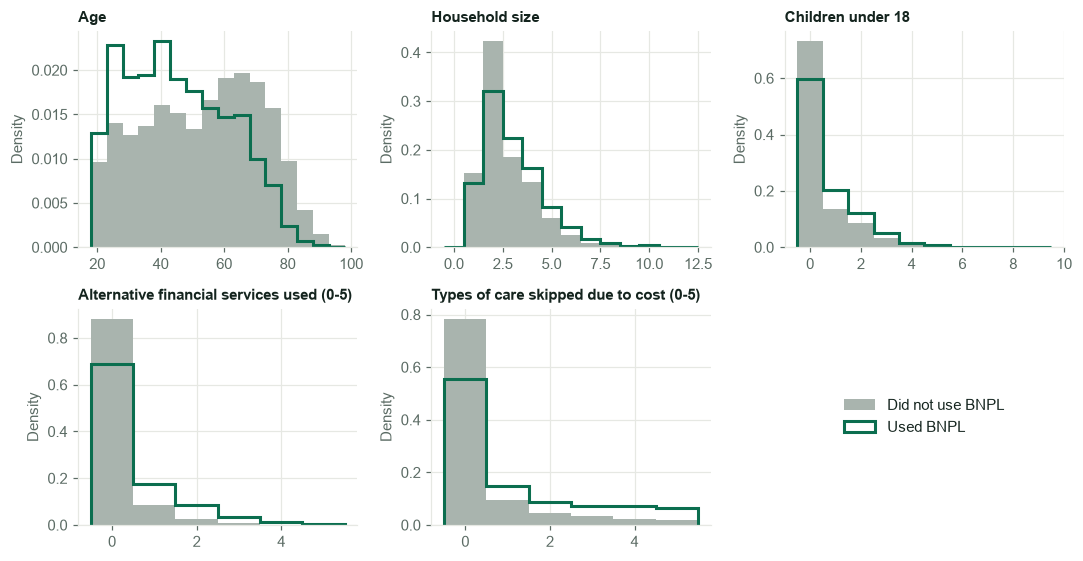

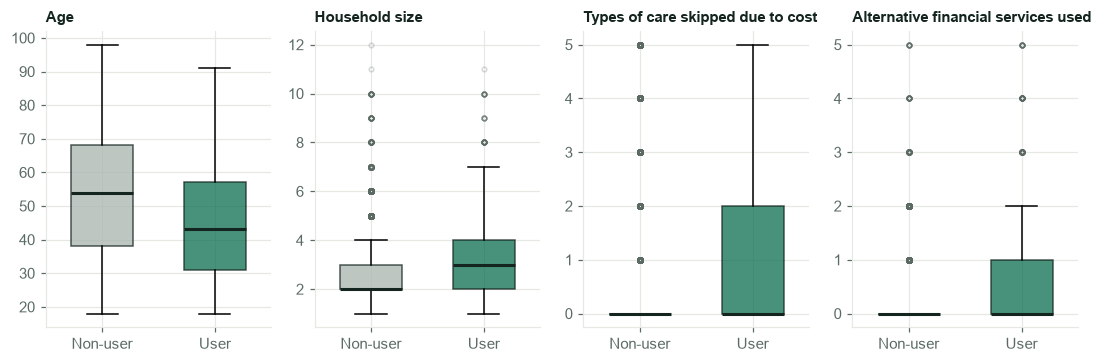

In [10]:
fig = plots.histograms(df); plt.show()
fig = plots.boxplots(df); plt.show()

Users are younger (median 43 against 54), live in slightly larger households, and more often skip care because of cost. The boxes overlap heavily, so no single variable separates the classes; a model has to combine several.

### 5.5 BNPL use by demographic group
*Purpose:* find which groups use BNPL more, and compare weighted with unweighted rates.

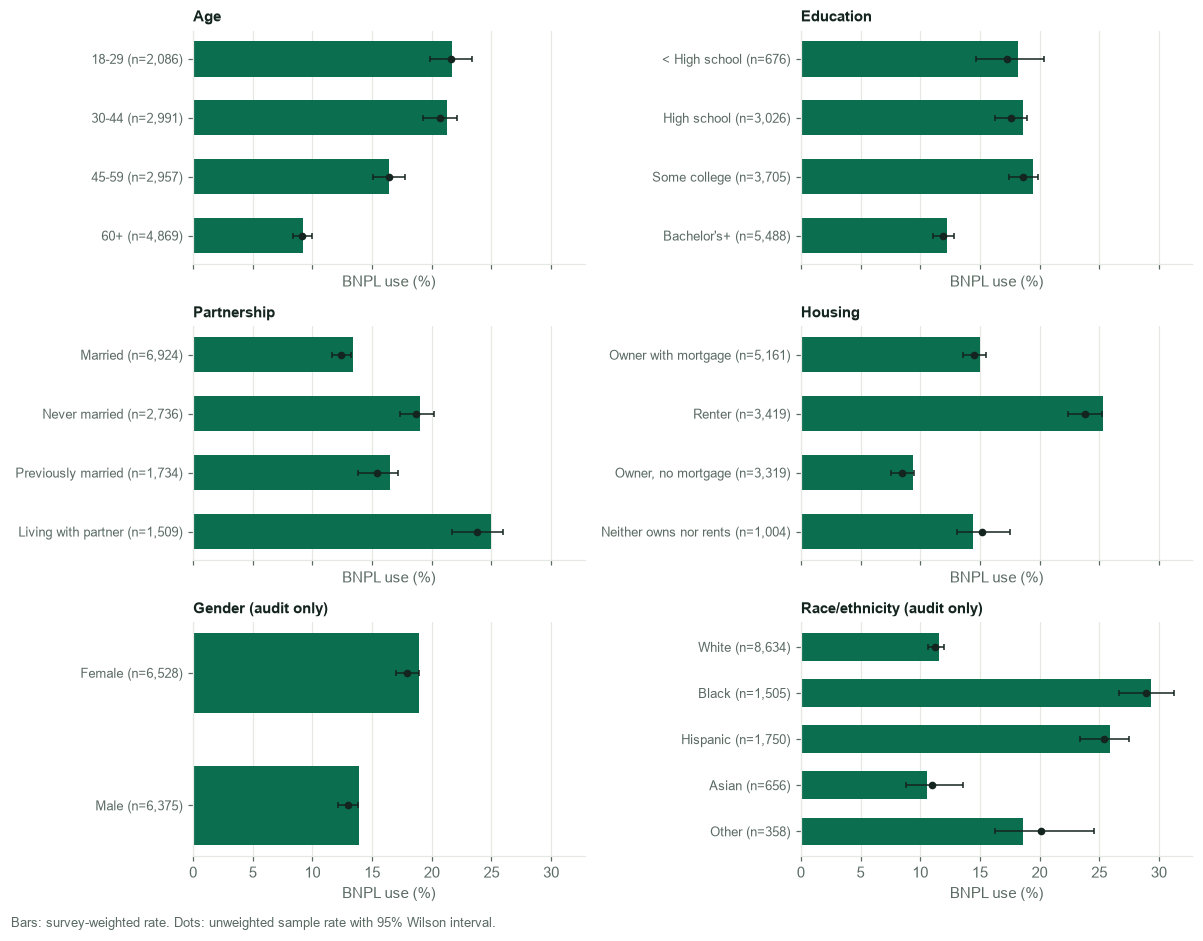

In [11]:
fig = plots.demographics(df); plt.show()

Use falls from about 22% below age 45 to 9% at 60 and over. Renters and people living with a partner use it more; people with a degree use it less. Black (29%) and Hispanic (26%) adults report more than twice the rate of White (12%) and Asian (11%) adults. Gender and race are shown for context and are **not** model inputs (section 15).

### 5.6 Income and financial condition
*Purpose:* test the business intuition that BNPL is about low income.

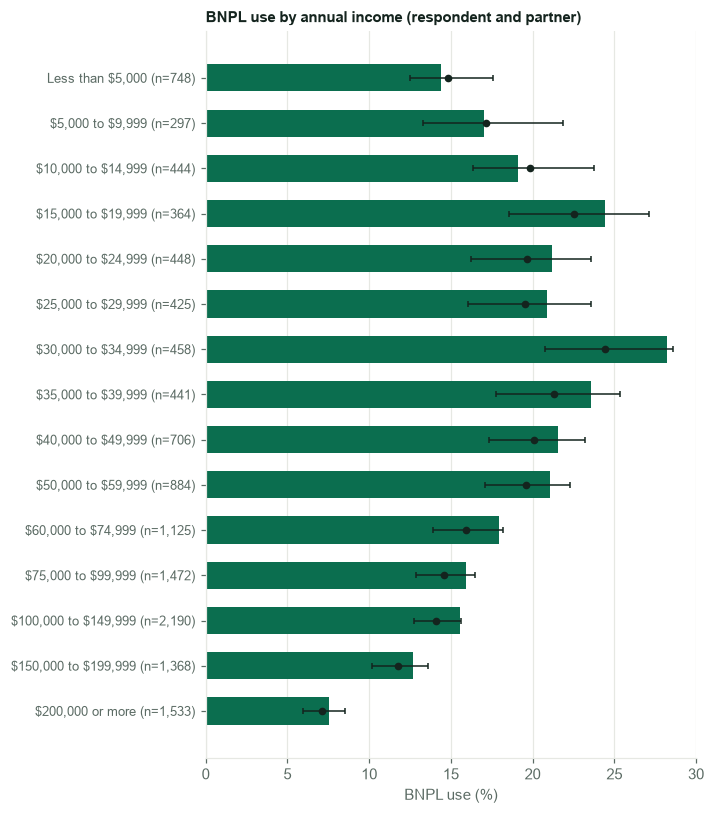

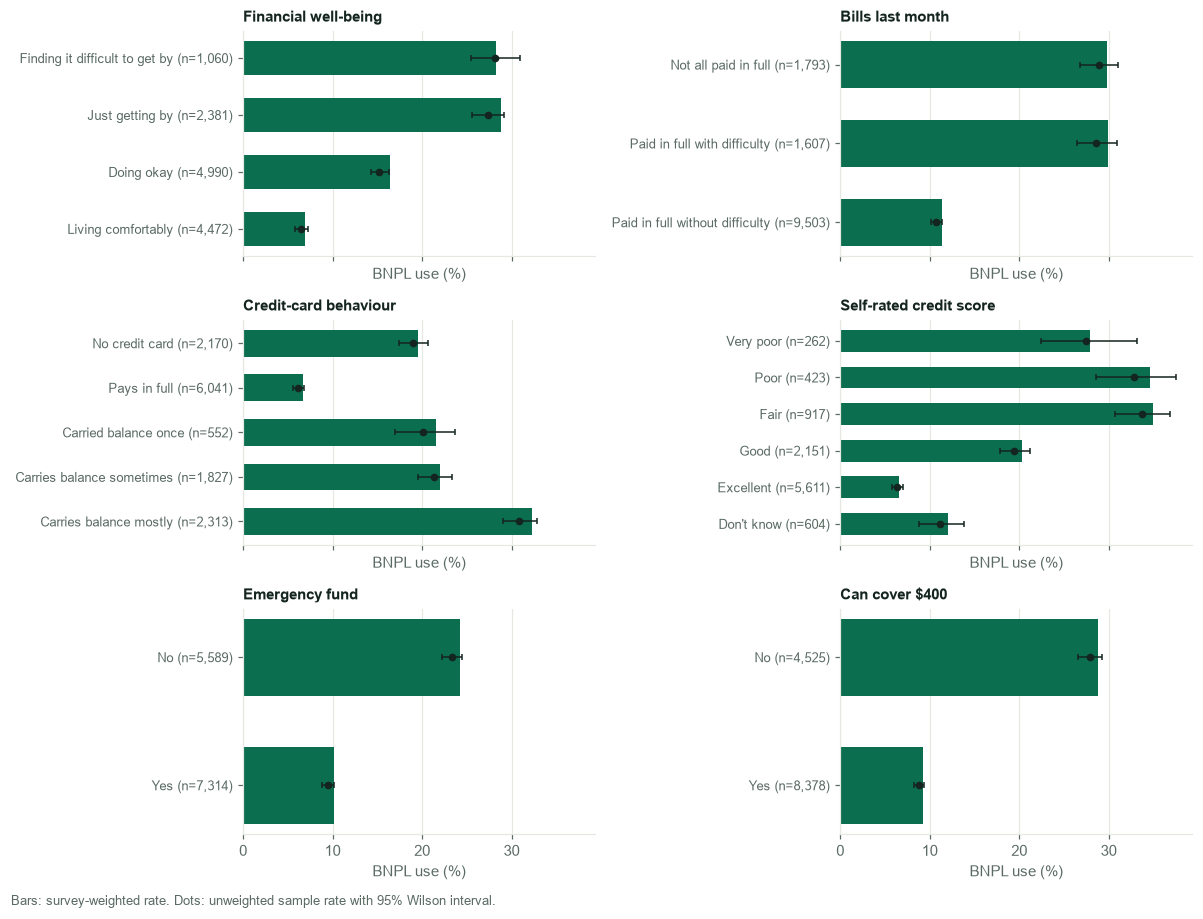

In [12]:
fig = plots.income(df); plt.show()
fig = plots.finance(df); plt.show()

**Income is not a straight line.** Use rises from about 14% in the lowest band to 28% around $30,000-$35,000 (weighted) and then falls to 8% above $200,000. **Financial strain matters more than income.** Use is about 29% among people just getting by or finding it difficult and 7% among people living comfortably; it is about three times higher among people who cannot cover $400. People who usually carry a card balance use BNPL about five times as often as people who pay in full, so BNPL seems to sit alongside card borrowing rather than replace it.

### 5.7 Multivariate view
*Purpose:* check whether the effects of income, well-being and age simply add up or interact.

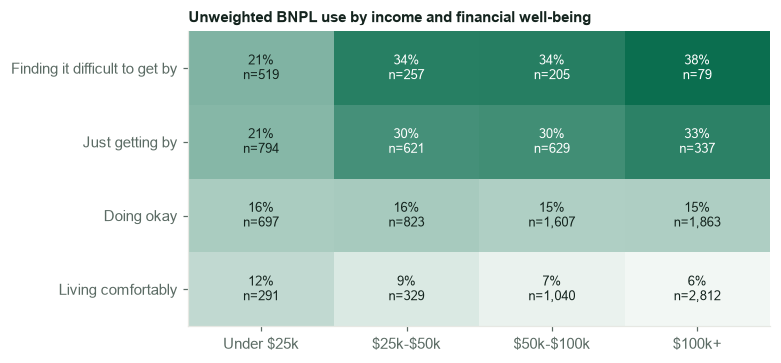

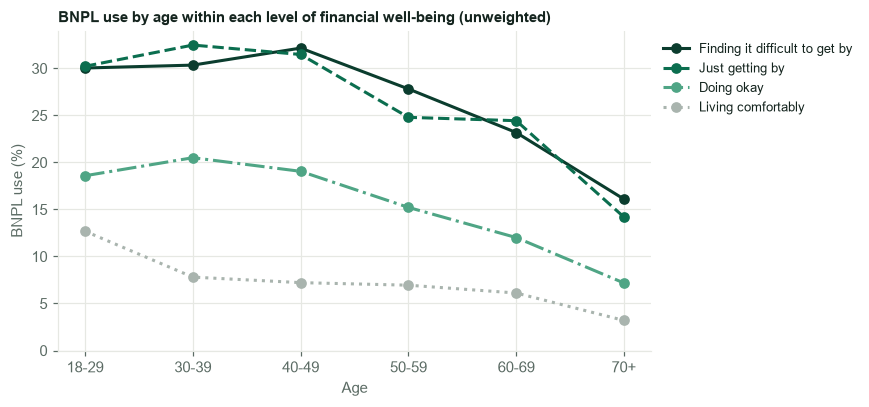

In [13]:
fig = plots.heat_income_wellbeing(df); plt.show()
fig = plots.age_by_wellbeing(df); plt.show()

Among people who are struggling, use is *higher* at middle and higher incomes (34-38%) than at the lowest income (21%); among comfortable people it falls with income. The $100k+ "finding it difficult" cell has only 79 respondents, so its 38% is imprecise. This interaction is why tree ensembles, which can learn interactions, are included in the comparison.

### 5.8 Correlation and association
*Purpose:* measure strength of association with a statistic suited to each variable type. Pearson correlation on category codes would be meaningless, so **Spearman** is used for numeric and ordered variables, bias-corrected **Cramer's V** for categorical ones and the **rank-biserial** correlation for numeric variables against the target.

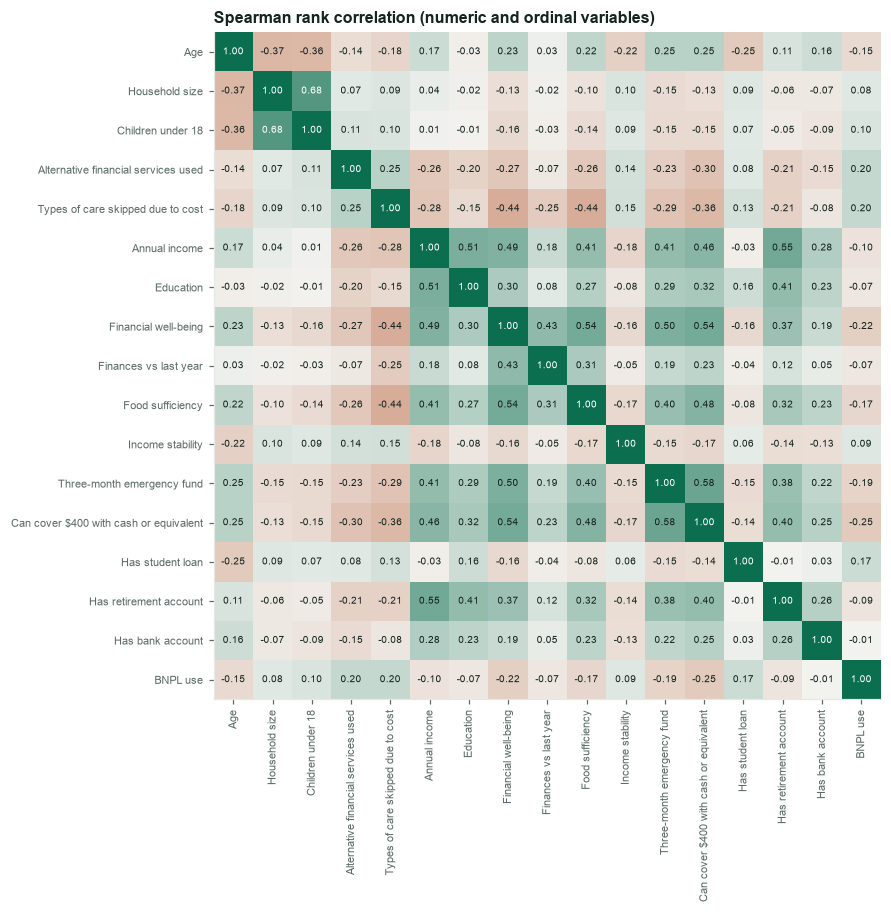

In [14]:
fig = plots.spearman(df); plt.show()

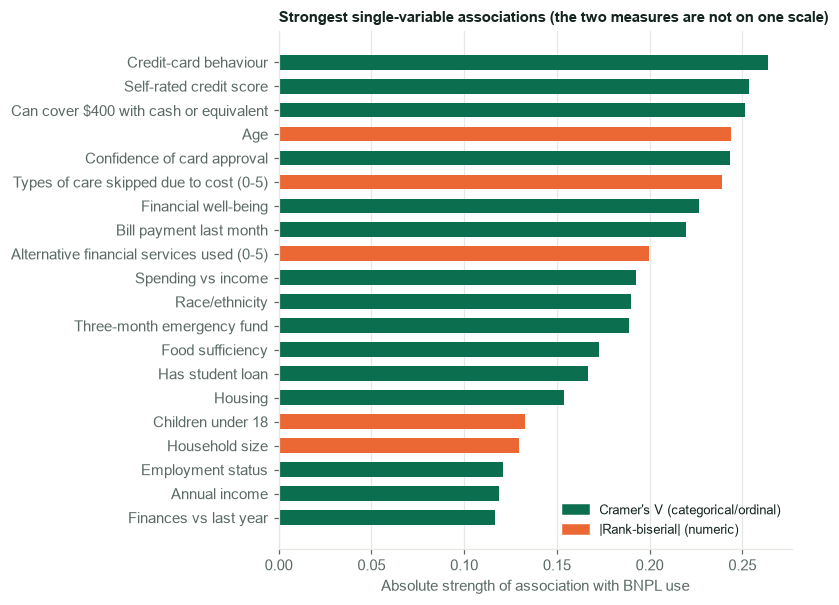

,Label,Measure,Strength,Holm-adjusted p
0,Credit-card behaviour,Cramer's V (chi-square),0.2636,0.0
1,Self-rated credit score,Cramer's V (chi-square),0.2535,0.0
2,Can cover $400 with cash or equivalent,Cramer's V (chi-square),0.2516,0.0
3,Age,Rank-biserial (Mann-Whitney),-0.2441,0.0
4,Confidence of card approval,Cramer's V (chi-square),0.2434,0.0
5,Types of care skipped due to cost (0-5),Rank-biserial (Mann-Whitney),0.2392,0.0
6,Financial well-being,Cramer's V (chi-square),0.2265,0.0
7,Bill payment last month,Cramer's V (chi-square),0.2194,0.0
8,Alternative financial services used (0-5),Rank-biserial (Mann-Whitney),0.1996,0.0
9,Spending vs income,Cramer's V (chi-square),0.1929,0.0


,Feature,Label,VIF
0,household_size,Household size,2.27
1,children_u18,Children under 18,2.24
2,financial_wellbeing,Financial well-being,2.22
3,income_band,Annual income,2.01
4,can_cover_400,Can cover $400 with cash or equivalent,1.95
5,food_security,Food sufficiency,1.73


In [15]:
assoc = ex.save(eda.association(df), "association")
ex.save(eda.spearman_matrix(df), "spearman", index=True)
fig = plots.association(assoc); plt.show()
display(assoc[["Label", "Measure", "Strength", "Holm-adjusted p"]].head(12).round(4))
display(ex.save(eda.vif(df), "vif").round(2).head(6))

Credit-card behaviour (V = 0.26), self-rated credit score (0.25) and covering a $400 expense (0.25) are the strongest single associations, and all are modest. Holding a bank account shows no association on its own. With 12,903 rows almost everything is "statistically significant", so effect size matters more than the p-value. The largest variance inflation factor is 2.3, well below the usual concern level of 5-10, so multicollinearity does not threaten Logistic Regression.

## 6. Feature selection
Features were chosen from the codebook on relevance, data quality, ethics and leakage, *before* any model was fitted. The table lists what was excluded and why.

In [16]:
display(excluded)
print(len(cfg.FEATURES), 'model inputs:', ', '.join(cfg.FEATURES))

,Excluded variable(s),Reason for exclusion
0,"BNPL1A, BNPL3, BNPL3A, BNPL4_a-g, BNPL5, BNPL6_a-g, BNPL7_a-b","Target leakage: asked only of BNPL users, so being non-blank reveals the answer"
1,BNPL1_iflag and all *_iflag,"Survey imputation flags, not characteristics of the person"
2,"A0, A7_a-f, A1_a-c, A8, A2, A0B",Construct overlap: applying for 'other credit or loan' in the same 12 months may itsel...
3,BK2_f (overdraft fee),Possible consequence of BNPL: BNPL1A shows BNPL payments can trigger overdrafts
4,"EF8_h, EF3_f",Borrowing measures that may overlap with BNPL use
5,"EF7, EF7A",Split-sample question: each half of the sample saw a different answer scale
6,ppfsasset,34% missing and overlaps with EF1 and pay_casheqv
7,"ppemploy, ppinc7, ppeducat",Older panel-profile versions; the live survey answer is used instead
8,"ppage groups, inc_4cat_50k, pprent, atleast_okay",Duplicates of selected variables
9,"gender, race, pppa_lgb, pphispan",Protected characteristics: excluded on ethical grounds; gender and race kept for audit


26 model inputs: age, household_size, children_u18, afs_count, medical_skips, income_band, education, financial_wellbeing, change_vs_last_year, food_security, income_volatility, emergency_fund, can_cover_400, student_loan, retirement_account, bank_account, employment, partner_status, housing, region, metro, card_behaviour, credit_confidence, credit_score, spending_vs_income, bills_status


## 7. Data preprocessing
### 7.1 Error correction (row-wise, stateless, so it cannot leak)

In [17]:
display(log)

,Check,Rows affected
0,Duplicate respondent IDs removed,0
1,"Rows dropped: target answer was imputed by the survey, not reported",31
2,"Children corrected to at least 1 (survey says own child at home, profile says 0)",344
3,Household size raised to the minimum implied by partner and children,843
4,Education set to missing: graduate degree reported below age 22 (implausible),8
5,'Retired' under age 35 recoded to 'Not working' (implausible),16


**Rules.** (a) 31 target answers were *imputed by the survey team*; a model should learn from reported behaviour, so those rows are dropped (0.24%). (b) Panel-profile variables can be months older than the survey, so the live answer wins when they conflict. (c) Implausible combinations (graduate degree below 22; retired below 35) are recoded. (d) Nothing is deleted just for being unusual.

### 7.2 Learned preprocessing (fitted on training rows only)
| Step | Choice | Why |
|---|---|---|
| Missing nominal values | constant "Not reported" | non-response is informative (BNPL use differs) and it beat mode imputation in section 7.3 |
| Missing ordinal / numeric values | most frequent / median | only 8 education values; robust to skew |
| Outliers | winsorise household size at the training 99th percentile | keeps rows, limits leverage on linear coefficients |
| Ordered answers | ordinal encoding in codebook order | keeps the ordering with one column each |
| Unordered answers | one-hot encoding | avoids a false order |
| Scaling | standardisation | needed for a fair L1/L2 penalty in Logistic Regression; harmless for trees |
| New features | equivalised income, share of children, fragility score (0-6) | income must be judged against household size; hardship accumulates |

## 8. Train-test split
The test set is separated **before** any learned step. 60% train, 20% validation, 20% test, stratified on the target with a fixed seed.

In [18]:
train, valid, test = pl.split(df)
print(pd.DataFrame({n: {"rows": len(s), "BNPL users": int(s[cfg.TARGET].sum()), "rate": round(s[cfg.TARGET].mean(), 4)}
                    for n, s in [("train", train), ("validation", valid), ("test", test)]}))
assert not set(train.shedid) & set(test.shedid) and not set(valid.shedid) & set(test.shedid)
print()
print(ex.PROTOCOL)

                train  validation       test
rows        7741.0000    2581.000  2581.0000
BNPL users  1198.0000     400.000   399.0000
rate           0.1548       0.155     0.1546

Decision rules fixed BEFORE any model result was seen
1. The test set (20%) is used once, after model, strategy and threshold are fixed.
2. Primary metric: average precision (AP) - it focuses on the minority class. ROC-AUC, Brier, F1 etc. are secondary.
3. Hyperparameters: 5-fold stratified CV on the training set (60%), maximising AP.
4. Imbalance strategy: keep 'No balancing' unless another strategy raises mean CV AP by more than 0.005
   (a smaller gain does not justify distorted probabilities).
5. Model: among models whose CV AP is within one standard error of the best, take the simplest
   (Logistic Regression < Decision Tree < Random Forest < Gradient Boosting).
6. Threshold: the value maximising F1 on the validation set (20%).
7. Gender and race are excluded as inputs on ethical grounds; their effect i

In [19]:
# The preprocessing pipeline as an object, and what it produces for the training rows
pipe = pl.build("Logistic Regression")
display(pipe)
X, y = pl.xy(train)
Z = pd.DataFrame(pipe.fit(X, y)[:-1].transform(X), columns=pl.transformed_names(pipe)[0])
print(X.shape, "->", Z.shape, "| missing values left:", int(Z.isna().sum().sum()))
display(pd.DataFrame({"mean before": X[cfg.NUMERIC].mean(), "sd before": X[cfg.NUMERIC].std(),
                      "mean after": Z[cfg.NUMERIC].mean(), "sd after": Z[cfg.NUMERIC].std()}).round(3))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('engineer', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,derive,True
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('ord', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g.

(7741, 26) -> (7741, 58) | missing values left: 0


,mean before,sd before,mean after,sd after
age,51.371,18.153,0.0,1.0
household_size,2.733,1.434,0.0,1.0
children_u18,0.511,0.965,0.0,1.0
afs_count,0.224,0.626,-0.0,1.0
medical_skips,0.577,1.210,-0.0,1.0


### 7.3 Do the preprocessing choices matter? (cross-validation on training rows)

In [20]:
display(ex.preprocessing_choices(train).round(4))

,Choice,Model,CV AP,CV AP SE,CV ROC-AUC,CV Brier
0,"Credit score: 'Not reported' category, scaled",Logistic Regression,0.4113,0.0131,0.7826,0.1108
1,"Credit score: 'Not reported' category, scaled",Random Forest,0.4097,0.0109,0.7778,0.1118
2,"Credit score: most-frequent imputation, scaled",Logistic Regression,0.4060,0.0151,0.7793,0.1113
3,"Credit score: most-frequent imputation, scaled",Random Forest,0.4056,0.0121,0.7764,0.1121
4,"Credit score: 'Not reported' category, not scaled",Logistic Regression,0.4106,0.0139,0.7819,0.1109
5,"Credit score: 'Not reported' category, not scaled",Random Forest,0.4096,0.0109,0.7778,0.1118
6,No engineered features,Logistic Regression,0.4104,0.0135,0.7824,0.1109
7,No engineered features,Random Forest,0.4121,0.0092,0.7769,0.1118


Keeping non-response as a category is better than imputing the most frequent value for both models (AP 0.411 against 0.406 for Logistic Regression), although the gain is within one standard error. Scaling barely changes the result here. The engineered features give a tiny gain for Logistic Regression (0.4113 against 0.4104) and a small loss for Random Forest, which can build such combinations itself; they are kept because they are interpretable, not because they raise the score.

### 7.4 Feature-set ablation: which information helps?

In [21]:
display(ex.ablation(train).round(4))

,Feature set,Features,CV AP,CV AP SE,CV ROC-AUC,CV Brier
0,Demographics only,9,0.2580,0.0104,0.6642,0.1252
1,+ Income,12,0.2970,0.0114,0.6987,0.1219
2,+ Financial well-being,17,0.3143,0.0104,0.7254,0.1199
3,+ Resilience,20,0.3310,0.0125,0.7407,0.1181
4,+ Credit and banking (all 26),26,0.4104,0.0135,0.7824,0.1109
5,All 26 + engineered features,29,0.4113,0.0131,0.7826,0.1108
6,All + engineered + gender and race (audit only),31,0.4215,0.0147,0.7879,0.1099


Demographics alone reach AP 0.258. Adding income, well-being and resilience raises it to 0.331, and credit and banking behaviour to 0.410, the largest single step. Adding gender and race would raise AP only from 0.411 to 0.422. That gain, smaller than one standard error, is knowingly given up on ethical grounds.

## 9. Baseline model
A `DummyClassifier` predicts the base rate for everyone. Any useful model must beat its AP, which equals the positive rate.

In [22]:
from sklearn.metrics import accuracy_score, recall_score
Xv, yv = pl.xy(valid)
dummy = pl.build("Dummy").fit(X, y)
print("Dummy, validation: accuracy", round(accuracy_score(yv, dummy.predict(Xv)), 3), "| recall", recall_score(yv, dummy.predict(Xv)))

Dummy, validation: accuracy 0.845 | recall 0.0


## 10. Model training
| Model | How it works | Assumptions and bias | Why included |
|---|---|---|---|
| **Logistic Regression** | Weighted sum of inputs turned into a probability by the logistic function | Effects add up on the log-odds scale; needs scaling; sensitive to strong collinearity | Transparent, usually well calibrated, hard to overfit |
| **Decision Tree** | Repeated yes/no splits that make groups purer | High variance; step-like predictions; greedy splits | Readable rules; finds interactions |
| **Random Forest** | Averages many trees grown on bootstrap samples with random feature subsets | Less interpretable; pulls probabilities toward the middle; impurity importance favours many-valued inputs | Cuts the variance of a single tree |
| **Gradient Boosting** (histogram) | Adds small trees one by one, each correcting earlier errors | Can overfit; sensitive to learning rate and tree size | Often the strongest choice for tabular data, so it tests whether complexity pays |

All four are supervised classifiers. Section 11 tunes them; the settings before tuning appear in the same table.

## 11. Hyperparameter tuning
Done before the imbalance experiments because those use the tuned settings. Five-fold stratified cross-validation on training rows, maximising average precision.

In [23]:
for m, g in ex.GRIDS.items():
    print(m, {k.replace("clf__", ""): v for k, v in g.items()})
tuning, best = ex.tune(train)
display(tuning.round(4))
for m, p in best.items(): print(m, p)

Logistic Regression {'C': [0.001, 0.00316, 0.01, 0.03162, 0.1, 0.31623, 1.0, 3.16228, 10.0], 'l1_ratio': [0.0, 0.5, 1.0]}
Decision Tree {'max_depth': [3, 4, 5, 6, 8, 10, None], 'min_samples_leaf': [1, 10, 25, 50, 100, 200], 'criterion': ['gini', 'log_loss'], 'ccp_alpha': [0.0, 0.0005, 0.001, 0.002]}
Random Forest {'max_depth': [6, 8, 10, 14, None], 'min_samples_leaf': [1, 3, 5, 10, 20], 'max_features': ['sqrt', 0.2, 0.35, 0.5]}
Gradient Boosting {'learning_rate': [0.02, 0.05, 0.1], 'max_iter': [100, 200, 400], 'max_leaf_nodes': [4, 8, 15, 31], 'min_samples_leaf': [20, 50, 100], 'l2_regularization': [0.0, 1.0, 10.0]}


,Model,Settings,CV AP,CV AP SE,CV ROC-AUC,CV Brier,Train AP,Gap (train-CV)
0,Dummy,baseline,0.1548,0.0002,0.5000,0.1308,0.1548,0.0000
1,Logistic Regression,default,0.4113,0.0131,0.7826,0.1108,0.4302,0.0189
2,Logistic Regression,tuned,0.4145,0.0130,0.7830,0.1106,0.4247,0.0103
3,Decision Tree,default,0.1825,0.0050,0.5627,0.2385,1.0000,0.8175
4,Decision Tree,tuned,0.3466,0.0109,0.7470,0.1165,0.3996,0.0530
5,Random Forest,default,0.3882,0.0119,0.7646,0.1137,1.0000,0.6118
6,Random Forest,tuned,0.4153,0.0114,0.7799,0.1115,0.5878,0.1724
7,Gradient Boosting,default,0.3731,0.0168,0.7522,0.1169,0.9007,0.5275
8,Gradient Boosting,tuned,0.4168,0.0097,0.7789,0.1111,0.5048,0.0880


Logistic Regression {'C': 0.1, 'l1_ratio': 1.0}
Decision Tree {'min_samples_leaf': 100, 'max_depth': 10, 'criterion': 'log_loss', 'ccp_alpha': 0.0}
Random Forest {'min_samples_leaf': 1, 'max_features': 0.35, 'max_depth': 6}
Gradient Boosting {'min_samples_leaf': 100, 'max_leaf_nodes': 4, 'max_iter': 200, 'learning_rate': 0.1, 'l2_regularization': 10.0}


**Reading the table.** *Gap* is training AP minus cross-validated AP. An untuned Decision Tree and Random Forest memorise the training rows (training AP 1.000). Tuning cuts the tree's gap from 0.82 to 0.05 and nearly doubles its CV AP. Logistic Regression has the smallest gap (0.010), so it is the least overfitted. Its best penalty is the lasso (`l1_ratio = 1`, `C = 0.1`), which shrinks weak terms to zero and so also performs feature selection.

## 12. Class imbalance experiments
Each tuned model is trained with four strategies. Resampling happens inside the training folds only.

,Model,Strategy,CV AP,CV AP SE,CV ROC-AUC,CV Brier,Valid AP,Valid Brier,Mean predicted,Actual rate,Recall @0.50,Precision @0.50,F1 @0.50,Best-F1 threshold,Recall @best,Precision @best,F1 @best
0,Logistic Regression,No balancing,0.414,0.013,0.783,0.111,0.438,0.109,0.158,0.155,0.155,0.620,0.248,0.23,0.588,0.386,0.466
1,Logistic Regression,Class weights,0.412,0.013,0.783,0.189,0.434,0.191,0.418,0.155,0.720,0.307,0.430,0.62,0.582,0.375,0.456
2,Logistic Regression,Random oversampling,0.409,0.013,0.782,0.188,0.436,0.190,0.415,0.155,0.718,0.311,0.434,0.63,0.568,0.382,0.457
3,Logistic Regression,SMOTENC,0.348,0.010,0.737,0.182,0.360,0.180,0.373,0.155,0.592,0.304,0.402,0.59,0.500,0.350,0.412
4,Decision Tree,No balancing,0.347,0.011,0.747,0.117,0.342,0.118,0.156,0.155,0.098,0.494,0.163,0.19,0.572,0.315,0.406
5,Decision Tree,Class weights,0.345,0.012,0.745,0.201,0.362,0.205,0.409,0.155,0.728,0.266,0.390,0.65,0.518,0.343,0.412
6,Decision Tree,Random oversampling,0.315,0.009,0.728,0.199,0.328,0.200,0.390,0.155,0.668,0.274,0.389,0.61,0.530,0.333,0.409
7,Decision Tree,SMOTENC,0.296,0.008,0.699,0.172,0.342,0.160,0.308,0.155,0.478,0.333,0.393,0.48,0.498,0.328,0.396
8,Random Forest,No balancing,0.415,0.011,0.780,0.111,0.416,0.111,0.158,0.155,0.045,0.600,0.084,0.21,0.645,0.341,0.446
9,Random Forest,Class weights,0.402,0.007,0.776,0.184,0.408,0.188,0.411,0.155,0.742,0.293,0.421,0.60,0.590,0.368,0.453


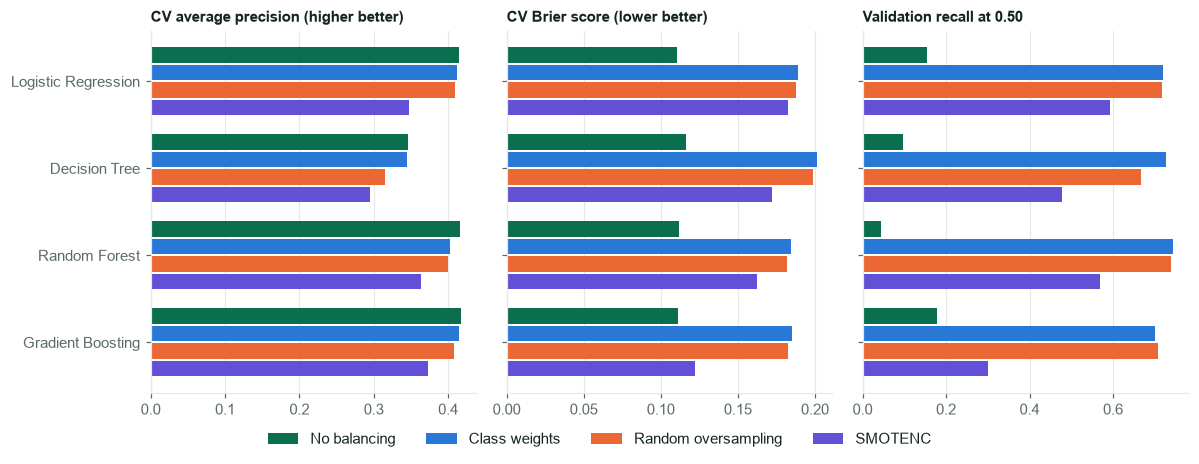

In [24]:
imb = ex.imbalance(train, valid, best)
display(imb.round(3))
fig = plots.imbalance(imb); plt.show()

**Findings.** (1) No strategy improves ranking quality: CV AP is highest without balancing for all four models. (2) Balancing raises recall at the 0.50 threshold (Logistic Regression: 16% to 72%) but precision falls (62% to 31%), and the same trade is available by lowering the threshold. (3) Balancing damages probabilities: the mean predicted probability rises from 0.16 to about 0.42 while the true rate is 0.155, and the Brier score worsens from 0.11 to 0.19. (4) SMOTENC is worst, probably because it invents people between neighbours in a space that mixes ordered and categorical answers. This agrees with van den Goorbergh et al. (2022). By protocol rule 4 **no balancing** is used, and the threshold is adjusted instead.

In [25]:
selection, strategies, final = ex.choose(imb)
display(selection.round(4))
print("Selected:", final, "| strategies:", strategies)

,Model,Strategy,CV AP,CV AP SE,CV ROC-AUC,CV Brier,Valid AP,Valid Brier,Within 1 SE of best,Selected
0,Logistic Regression,No balancing,0.4145,0.0130,0.7830,0.1106,0.4379,0.1090,True,True
4,Decision Tree,No balancing,0.3466,0.0109,0.7470,0.1165,0.3422,0.1178,False,False
8,Random Forest,No balancing,0.4153,0.0114,0.7799,0.1115,0.4156,0.1114,True,False
12,Gradient Boosting,No balancing,0.4168,0.0097,0.7789,0.1111,0.4213,0.1097,True,False


Selected: Logistic Regression | strategies: {'Logistic Regression': 'No balancing', 'Decision Tree': 'No balancing', 'Random Forest': 'No balancing', 'Gradient Boosting': 'No balancing'}


**Model choice.** Gradient Boosting has the best CV AP (0.4168, SE 0.0097). Random Forest (0.4153) and Logistic Regression (0.4145) are within one standard error. By protocol rule 5 the simplest of them, **Logistic Regression**, is selected. The Decision Tree is clearly weaker.

### Decision threshold (validation set only)

{'Logistic Regression': 0.23, 'Decision Tree': 0.19, 'Random Forest': 0.21, 'Gradient Boosting': 0.28}


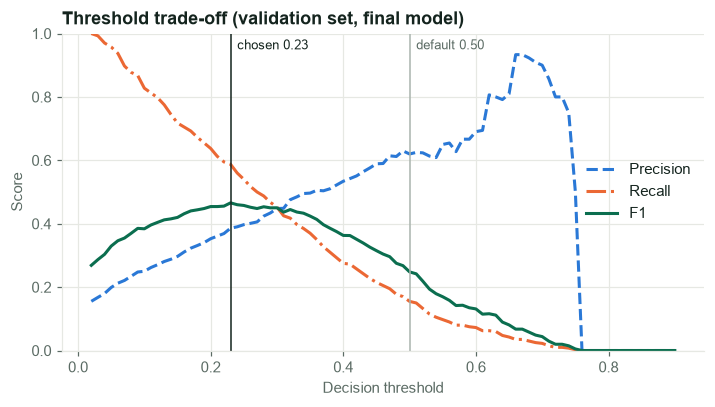

,Threshold,Precision,Recall,F1,Accuracy,Balanced accuracy,Flagged share,False positives,Missed users
8,0.10,0.250,0.828,0.384,0.589,0.686,0.513,993,69
13,0.15,0.297,0.718,0.420,0.693,0.703,0.375,680,113
18,0.20,0.353,0.638,0.454,0.762,0.711,0.280,468,145
21,0.23,0.386,0.588,0.466,0.791,0.708,0.236,374,165
28,0.30,0.448,0.452,0.450,0.829,0.675,0.157,223,219
38,0.40,0.534,0.275,0.363,0.850,0.615,0.080,96,290
48,0.50,0.620,0.155,0.248,0.854,0.569,0.039,38,338


In [26]:
th, vpred = ex.thresholds(train, valid, best, strategies)
tab = ex.save(ex.threshold_table(vpred["y"].to_numpy(), vpred[final].to_numpy()), "threshold_table")
print(th)
fig = plots.threshold(tab, th[final]); plt.show()
display(tab[tab.Threshold.isin([0.10, 0.15, 0.20, th[final], 0.30, 0.40, 0.50])].round(3))

At the default 0.50 the model finds only 16% of users. F1 peaks at 0.23, where it finds 59% of users and 39% of its flags are right. There is no single correct threshold: a survey team wanting more users could use 0.15; a team where false alarms are costly could use 0.30.

## 13. Model evaluation
Model, strategy and threshold are now fixed. Every model is refitted on train + validation and evaluated **once** on the test set.

In [27]:
meta = ex.save_metadata(final, strategies, th, best, {"train": train, "valid": valid, "test": test})
fitted = ex.final_fit(train, valid, best, strategies)
res, wres, ci, preds = ex.test_evaluation(fitted, test, th)
display(res.round(3))
display(ci.round(3))

,Model,Threshold,Accuracy,Balanced accuracy,Precision,Recall (TPR),TNR,F1,ROC-AUC,AP (PR-AUC),Brier,Log loss,TP,FP,FN,TN,Recall @0.50,F1 @0.50
0,Dummy,0.50,0.845,0.500,0.000,0.000,1.000,0.000,0.500,0.155,0.131,0.431,0,0,399,2182,NaN,NaN
1,Logistic Regression,0.23,0.792,0.698,0.382,0.561,0.834,0.455,0.789,0.426,0.109,0.356,224,362,175,1820,0.133,0.218
2,Decision Tree,0.19,0.740,0.679,0.317,0.591,0.767,0.413,0.748,0.350,0.116,0.430,236,508,163,1674,0.095,0.162
3,Random Forest,0.21,0.760,0.699,0.345,0.612,0.787,0.441,0.784,0.426,0.111,0.361,244,464,155,1718,0.055,0.103
4,Gradient Boosting,0.28,0.818,0.675,0.419,0.469,0.881,0.443,0.791,0.426,0.109,0.355,187,259,212,1923,0.133,0.214


,Model,AP low,AP high,ROC low,ROC high,AP diff vs LR,diff low,diff high
0,Logistic Regression,0.377,0.479,0.764,0.811,0.000,0.000,0.000
1,Decision Tree,0.308,0.397,0.722,0.772,-0.077,-0.107,-0.048
2,Random Forest,0.375,0.477,0.760,0.804,-0.000,-0.019,0.019
3,Gradient Boosting,0.377,0.477,0.766,0.813,0.000,-0.016,0.016


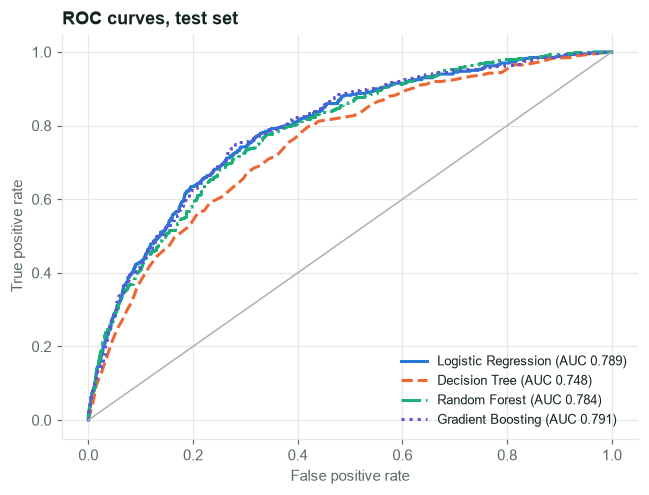

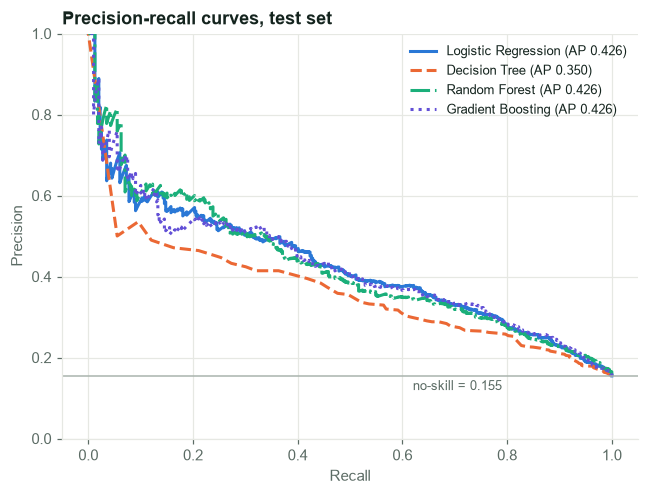

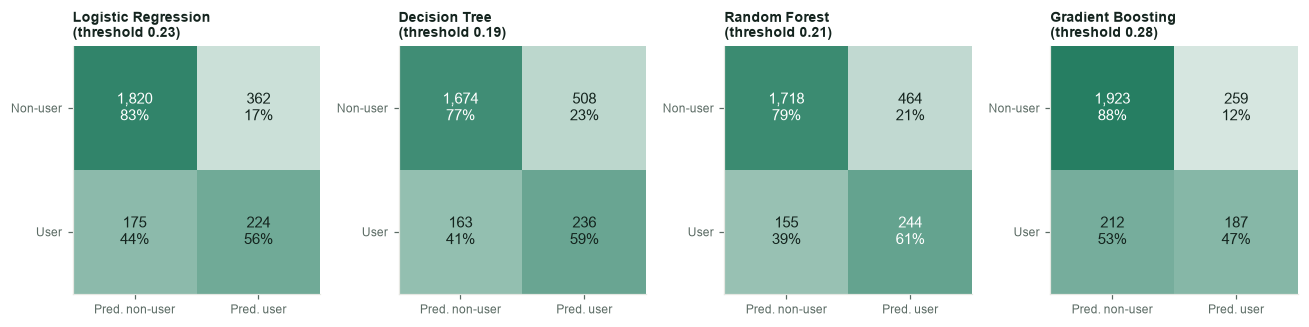

In [28]:
fig = plots.roc(preds, pl.MODEL_NAMES); plt.show()
fig = plots.pr(preds, pl.MODEL_NAMES); plt.show()
fig = plots.confusion(preds, th, pl.MODEL_NAMES); plt.show()

**Interpretation.** Logistic Regression, Random Forest and Gradient Boosting are indistinguishable on AP (0.426 each; paired bootstrap intervals for the differences include zero). The Decision Tree is significantly worse. Dummy accuracy (84.5%) is the highest of all although it finds no users, which is why accuracy is not the criterion. At its threshold Logistic Regression finds 224 of 399 users (56%) with 362 false alarms (precision 38%, 2.5 times the base rate). Gradient Boosting's F1 is slightly lower; the Random Forest finds more users (61%) with more false alarms.

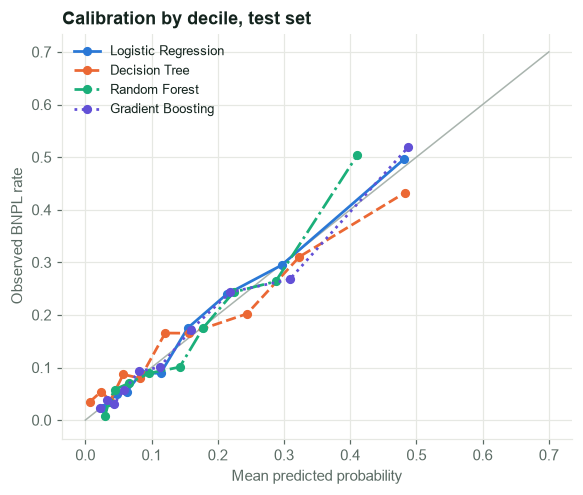

,Model,Threshold,Accuracy,Balanced accuracy,Precision,Recall (TPR),F1,ROC-AUC,AP (PR-AUC),Brier,Log loss
0,Dummy,0.50,0.832,0.500,0.000,0.000,0.000,0.500,0.168,0.140,0.453
1,Logistic Regression,0.23,0.783,0.705,0.400,0.588,0.476,0.795,0.453,0.115,0.370
2,Decision Tree,0.19,0.724,0.684,0.330,0.624,0.431,0.756,0.373,0.123,0.431
3,Random Forest,0.21,0.753,0.710,0.366,0.645,0.467,0.790,0.455,0.117,0.375
4,Gradient Boosting,0.28,0.808,0.679,0.435,0.485,0.458,0.797,0.450,0.115,0.369


In [29]:
cal = ex.calibration(preds)
fig = plots.calibration(cal, pl.MODEL_NAMES); plt.show()
display(wres.round(3))

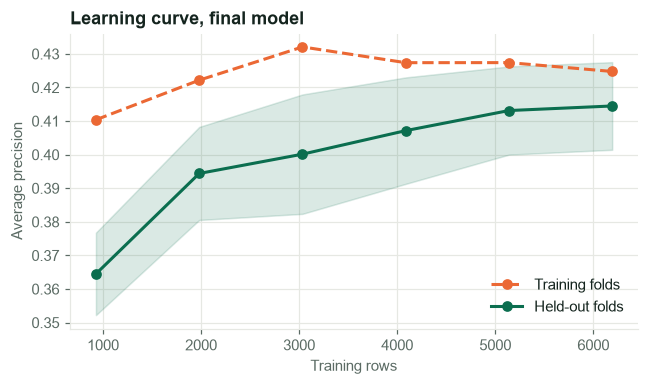

,Fit,Valid AP,Valid ROC-AUC,Weighted valid AP,Weighted valid ROC-AUC
0,Unweighted fit,0.4379,0.7843,0.4514,0.7828
1,Survey-weighted fit,0.4381,0.7864,0.4530,0.7848


In [30]:
lc = ex.learning(train, final, best[final], strategies[final])
fig = plots.learning(lc); plt.show()
display(ex.weight_sensitivity(train, valid, final, best[final], strategies[final]).round(4))

**Calibration.** Logistic Regression and Gradient Boosting follow the diagonal closely (Brier 0.109 for both against 0.131 for the dummy); predicted probabilities can be read as approximate rates in this population. **Learning curve.** Held-out AP is nearly flat after about 5,000 rows, so more rows of the same questions would add little. **Survey weights.** Fitting with weights changes validation AP by 0.0002, so the unweighted fit is kept.

## 14. Explainable AI

Terms kept by the lasso: 39 of 58


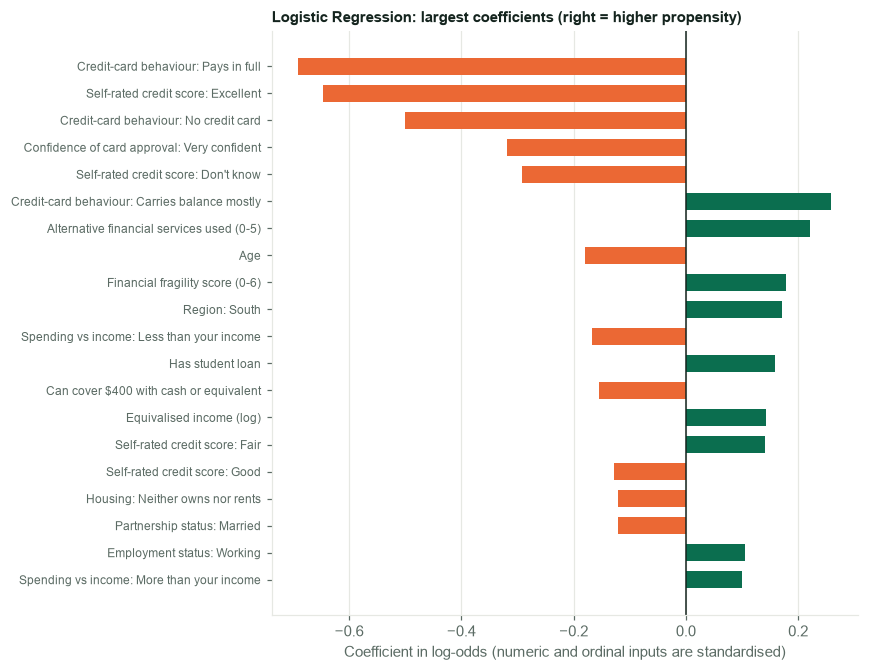

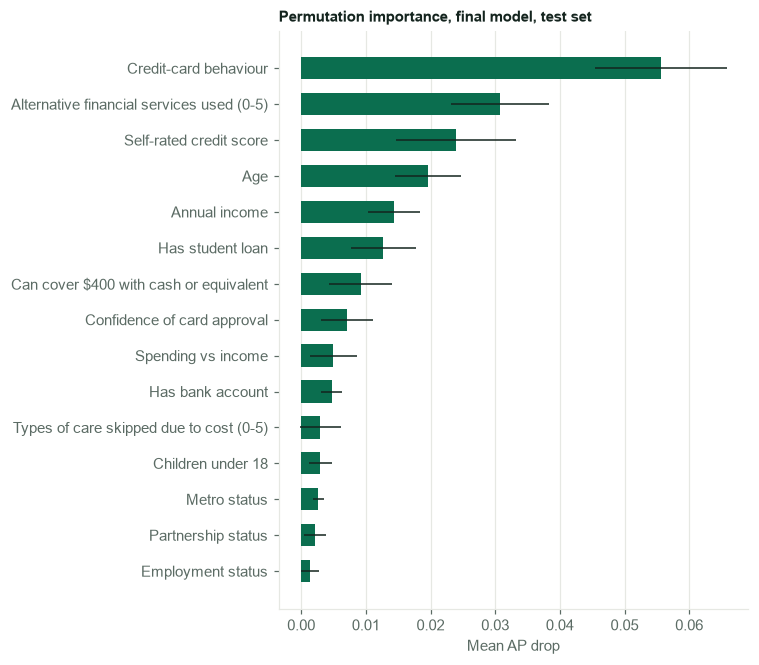

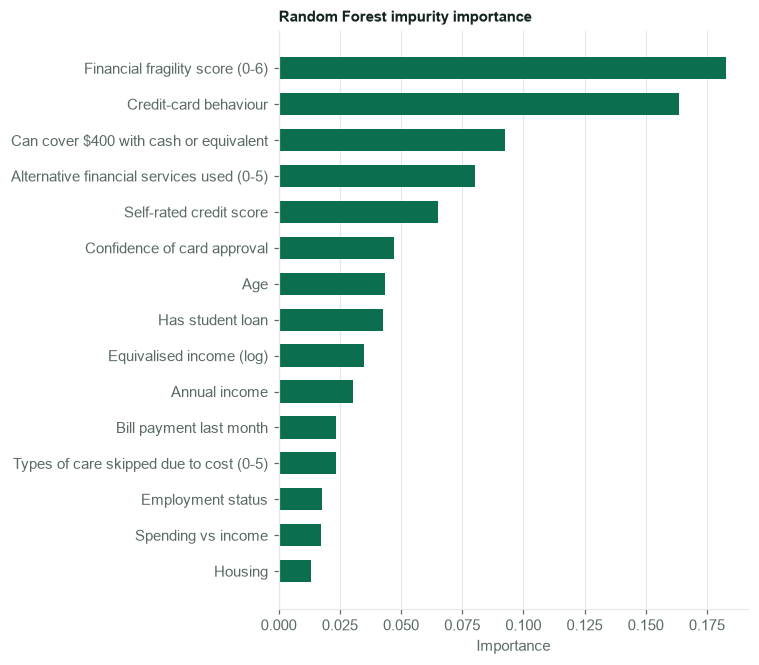

In [31]:
coef = ex.coefficients(fitted["Logistic Regression"])
print("Terms kept by the lasso:", int((coef.Coefficient != 0).sum()), "of", len(coef))
fig = plots.coefs(coef); plt.show()
perm = ex.permutation(fitted[final], test)
fig = plots.hbar(perm, "Label", "Mean AP drop", "Permutation importance, final model, test set", "30_permutation", err="SD"); plt.show()
rf = ex.tree_importance(fitted["Random Forest"])
fig = plots.hbar(rf, "Label", "Importance", "Random Forest impurity importance", "31_rf_importance"); plt.show()

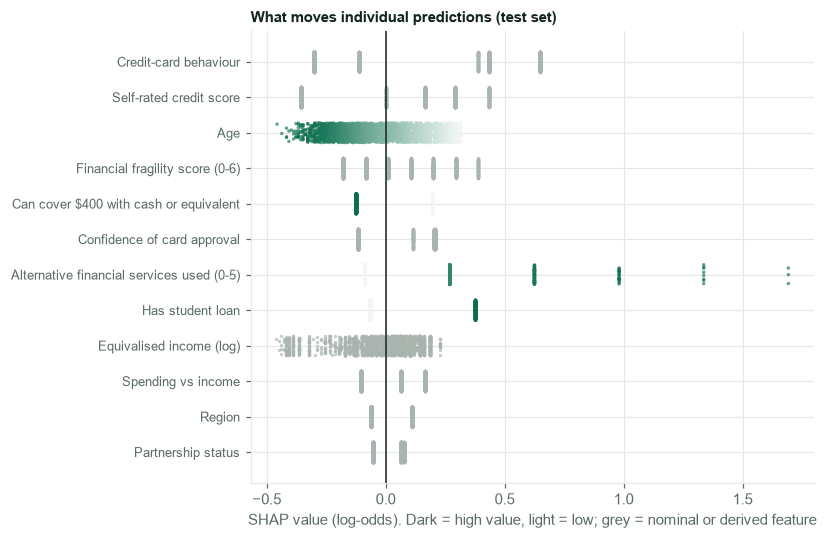

Predicted probability: 0.871 | rebuilt from contributions: 0.871


,Feature,phi,Label,Value
0,afs_count,1.343,Alternative financial services used (0-5),4
1,card_behaviour,0.613,Credit-card behaviour,Carries balance mostly
2,credit_score,0.446,Self-rated credit score,Fair
3,fragility_score,0.401,Financial fragility score (0-6),derived
4,student_loan,0.374,Has student loan,Yes
5,age,0.231,Age,28
6,can_cover_400,0.209,Can cover $400 with cash or equivalent,No
7,credit_confidence,0.206,Confidence of card approval,Not confident


In [32]:
dev = pd.concat([train, valid])
shap_imp, agg = ex.shap_summary(fitted[final], dev.sample(500, random_state=cfg.SEED), test)
fig = plots.shap_strip(agg, test[cfg.FEATURES].reset_index(drop=True), shap_imp); plt.show()

# One individual: exact contributions of a linear model
from bnpl import explain
row = test.iloc[int(np.argmax(preds[final]))]
profile = {f: ("Not reported" if pd.isna(row[f]) else (int(row[f]) if f in cfg.NUMERIC else row[f])) for f in cfg.FEATURES}
contrib, base = explain.contributions(fitted[final], profile, explain.background(fitted[final], dev[cfg.FEATURES]))
print("Predicted probability:", round(explain.predict(fitted[final], profile), 3),
      "| rebuilt from contributions:", round(1 / (1 + np.exp(-(base + contrib.phi.sum()))), 3))
display(contrib.head(8).round(3))

**Credit-card behaviour** ranks first in permutation importance, SHAP and the coefficients, and **self-rated credit score** and **age** are in the top four of both permutation importance and SHAP. The methods also disagree in an informative way: alternative financial services rank second by permutation but seventh by mean SHAP, because few people use them but those who do are ranked much higher. Paying the card in full, an excellent credit score and older age lower the estimate; carrying a balance, using alternative financial services and a higher fragility score raise it.

**Cautions.** (a) These are associations. BNPL use could also *cause* some measured strain. (b) Correlated inputs share importance, so one can look small because another stands in for it. (c) **Sign reversal:** use falls with income overall (section 5.6), but with credit score, savings and bills held fixed the income coefficients are positive. The raw trend is carried by the variables that go with income. The same applies to the emergency fund, which also feeds the fragility score. Coefficients answer a conditional question. (d) Logistic Regression cannot represent the income hump in section 5.6; the bound this puts on accuracy is small, because Gradient Boosting, which can, scores the same.

## 15. Ethical considerations

,Dimension,Group,n,BNPL users,Actual rate,Mean predicted,Flagged share,Recall (TPR),FPR,Precision,ROC-AUC
0,Gender,Female,1321,228,0.173,0.162,0.258,0.579,0.191,0.387,0.785
1,Gender,Male,1260,171,0.136,0.141,0.194,0.538,0.140,0.376,0.791
2,Race/ethnicity,Asian,137,15,0.109,0.113,0.117,0.467,0.074,0.438,0.821
3,Race/ethnicity,Black,283,81,0.286,0.241,0.435,0.691,0.332,0.455,0.730
4,Race/ethnicity,Hispanic,348,93,0.267,0.201,0.325,0.548,0.243,0.451,0.744
5,Race/ethnicity,Other,60,18,0.300,0.252,0.483,0.778,0.357,0.483,0.798
6,Race/ethnicity,White,1753,192,0.110,0.127,0.174,0.500,0.134,0.315,0.765
7,Age group,18-29,424,103,0.243,0.217,0.356,0.680,0.252,0.464,0.788
8,Age group,30-44,591,129,0.218,0.207,0.354,0.674,0.264,0.416,0.779
9,Age group,45-59,562,89,0.158,0.164,0.262,0.494,0.218,0.299,0.742


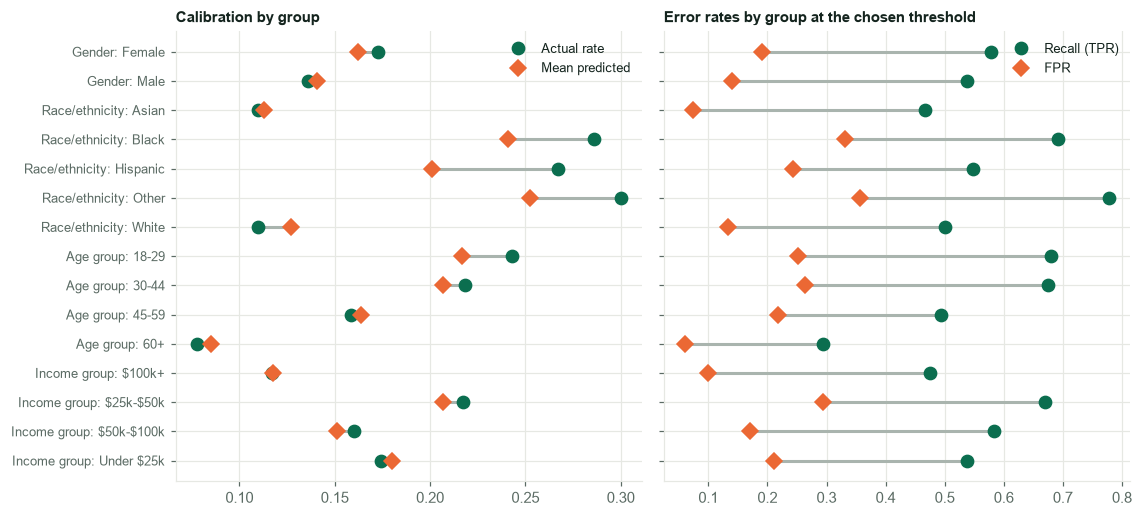

In [33]:
fair = ex.fairness(test, preds, final, th[final])
display(fair.round(3))
fig = plots.fairness(fair); plt.show()

Gender and race are not inputs, yet performance still differs. The model **under-predicts** for Hispanic respondents (20% predicted against 27% observed) and Black respondents (24% against 29%), and slightly over-predicts for White respondents. It finds 29% of users aged 60+ but 68% of those aged 18-29. "Fairness through unawareness" therefore does not guarantee equal performance (Mehrabi et al., 2021). Groups such as Asian (15 users) and Other (18 users) are too small for firm conclusions.

**Acceptable use:** research and consumer-protection planning. **Unacceptable use:** credit eligibility or pricing, marketing at financially strained people, inferring protected traits. Data are de-identified and public; the app stores nothing that users enter.

## 16. Final conclusions
1. **Answer.** Financial and demographic characteristics identify past-year BNPL users moderately well: test ROC-AUC 0.789 and AP 0.426, 2.8 times the no-skill level of 0.155.
2. **What matters.** Credit behaviour and perceived credit standing add most; demographics alone are weak.
3. **Simple was enough.** A lasso Logistic Regression matched Random Forest and Gradient Boosting, overfitted least and is well calibrated.
4. **Balancing did not help.** Class weights, oversampling and SMOTENC lowered or left ranking unchanged and damaged probabilities. Moving the threshold was enough.
5. **Limits.** One cross-section, self-reports, past-year recall, unclear time order (some predictors may follow BNPL use), US panel respondents, uneven performance by group.
6. **Future work.** Repeat on later SHED waves to test stability over time, add splines for income, examine group-specific recalibration, and use panel respondents to study time order.

*AI disclosure: this notebook was developed with substantial assistance from an AI coding assistant (Claude). The student must review, understand and be able to defend all content. See the report's AI-use statement.*